**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5061 - Operaciones de aprendizaje automático**

Tecnológico de Monterrey

Dr. Ivan Reyes Amezcua

Tutor: Alejandro Fortoul Díaz

**Semana 4**
Experimentacion

---

NOMBRE: Martha Patricia García Ángeles

MATRÍCULA: A01327744

---

Ahora el notebook sólo mantendrá la exploración de datos y el proceso tomado para la elección del modelo. El entrenamiento y la experimentación ahora se encuentran en un script localizado en /../src/train.py

## Paso 1: Carga y descripción de dataset:

### Importamos el dataset

In [48]:
#Importar las librerías necesarias
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Importar librerías de Scikit-learn para preprocesamiento, modelado y evaluación
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


Se eligió el dataset AI4I 2020 Predictive Maintenance Dataset del repositorio de la UCI Machine Learning. Es un dataset sintético que reune registros de mantenimiento predictivo en la industria (UCI, 2020)

In [49]:
#Cargar el dataset
maintenance_df = pd.read_csv('../data/raw/ai4i2020.csv')
#Imprimimos el encabezado del dataset
maintenance_df.head(10)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
5,6,M14865,M,298.1,308.6,1425,41.9,11,0,0,0,0,0,0
6,7,L47186,L,298.1,308.6,1558,42.4,14,0,0,0,0,0,0
7,8,L47187,L,298.1,308.6,1527,40.2,16,0,0,0,0,0,0
8,9,M14868,M,298.3,308.7,1667,28.6,18,0,0,0,0,0,0
9,10,M14869,M,298.5,309.0,1741,28.0,21,0,0,0,0,0,0


In [50]:
#Imprimimos las características del dataset
maintenance_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

#### Descripción del dataset
El dataset cuenta con 10,000 registros distribuidos en 12 columnas numéricas y 2 columnas que pueden contener texto y/o datos mixtos. 

Las variables que se identifican son:

**Categóricas**

- UDI: es una variable de identificación para cada registro, no aporta valor para el entrenamiento del modelo va del 1 al 10,000. 
- Product ID: es una variable de identificación para cada producto (único por producto), de igual manera que UDI, no aporta valor para el entrenamiento del modelo solo es una variable de identificación. 
- Tipo (Type):  indica los niveles de calidad de los productos que procesa la máquina. Puede tener 3 valores:L (Low), M (Medium) y H (High).

**Numéricas**

**Continuas**
- Temperatura del aire: indica en grados Kelvin la temperatura del ambiente, dato que se generó en revisiones aleatorias. 
- Temperatura del proceso: indica en grados Kelvin la temperatura del proceso, dato que se generó en revisiones aleatorias. 
- Velocidad rotacional: indica en revoluciones por minuto (rpm) del motor de la máquina.
- Torque: indica en Nm, la fuerza que requiere para mover la carga de la máquina.
- Desgaste de la herramienta: indica los minutos que representan el desgaste que tiene el herramental  en el proceso. 

Todas estas variables se esperan que sean valores positivos debido a su naturaleza. 


**Discretas booleanas**
- Falla de la máquina: es una variable booleana que indica si hubo o no una falla en la máquina. 

Tipos de fallas:
- Falla por desgaste (TWF): indica si el herramental fue reemplazado debido a una falla por desgaste. 
- Falla por disipación de calor (HDF): indica si hubo un sobrecalentamiento durante el proceso al no haber una correcta disipación del calor. 
- Falla por potencia (PWF): indica si hubo una falla en la potencia requerida para el proceso. 
- Falla por sobreesfuerzo o fatiga (OSF): indica si hubo una falla por exceder el umbral entre el producto del torque y el desgaste.  
- Falla aleatoria (RNF): representa las fallas que pueden ocurrir sin importar las condiciones que se tengan en el proceso. 


## Paso 2. Análisis exploratorio (EDA)

### Estadísticas descriptivas de las variables

In [51]:
#Estadísticas descriptivas del dataset
print('Valores descriptivos de las columnas numéricas:')
maintenance_df.describe()

Valores descriptivos de las columnas numéricas:


,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [52]:
#Estadísticas descriptivas de las columnas categóricas
print('Datos descriptivos de columnas categóricas')
maintenance_df.describe(include=['str'])

Datos descriptivos de columnas categóricas


,Product ID,Type
count,10000,10000
unique,10000,3
top,M14860,L
freq,1,6000


In [53]:
# Frecuencia de cada tipo de producto (L, M, H)
maintenance_df['Type'].value_counts()

Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

In [54]:
# Verificar que cada Product ID sea único
maintenance_df['Product ID'].is_unique

True

### Evaluación de la distribución de las variables

Para efectos de análisis descriptivo gráfico, se descartan las variables de identificación y booleanas.

In [55]:
# Variables numéricas continuas que se usarán como features
num_cols = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]

In [56]:
est_desc = maintenance_df[num_cols].describe().T #Traspuesta del df obtenido de la función .describe()
est_desc['skew']=maintenance_df[num_cols].skew() #Agregando valores de skew / simetría
est_desc['kurtosis']=maintenance_df[num_cols].kurtosis() #Agregando valores de curtosis
print('Valores descriptivos de las columnas numéricas')
est_desc

Valores descriptivos de las columnas numéricas


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5,0.114274,-0.835962
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8,0.015027,-0.499734
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0,1.993171,7.392945
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6,-0.009517,-0.013241
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.0,108.0,162.0,253.0,0.027292,-1.166737


Histogramas de las columnas numéricas:


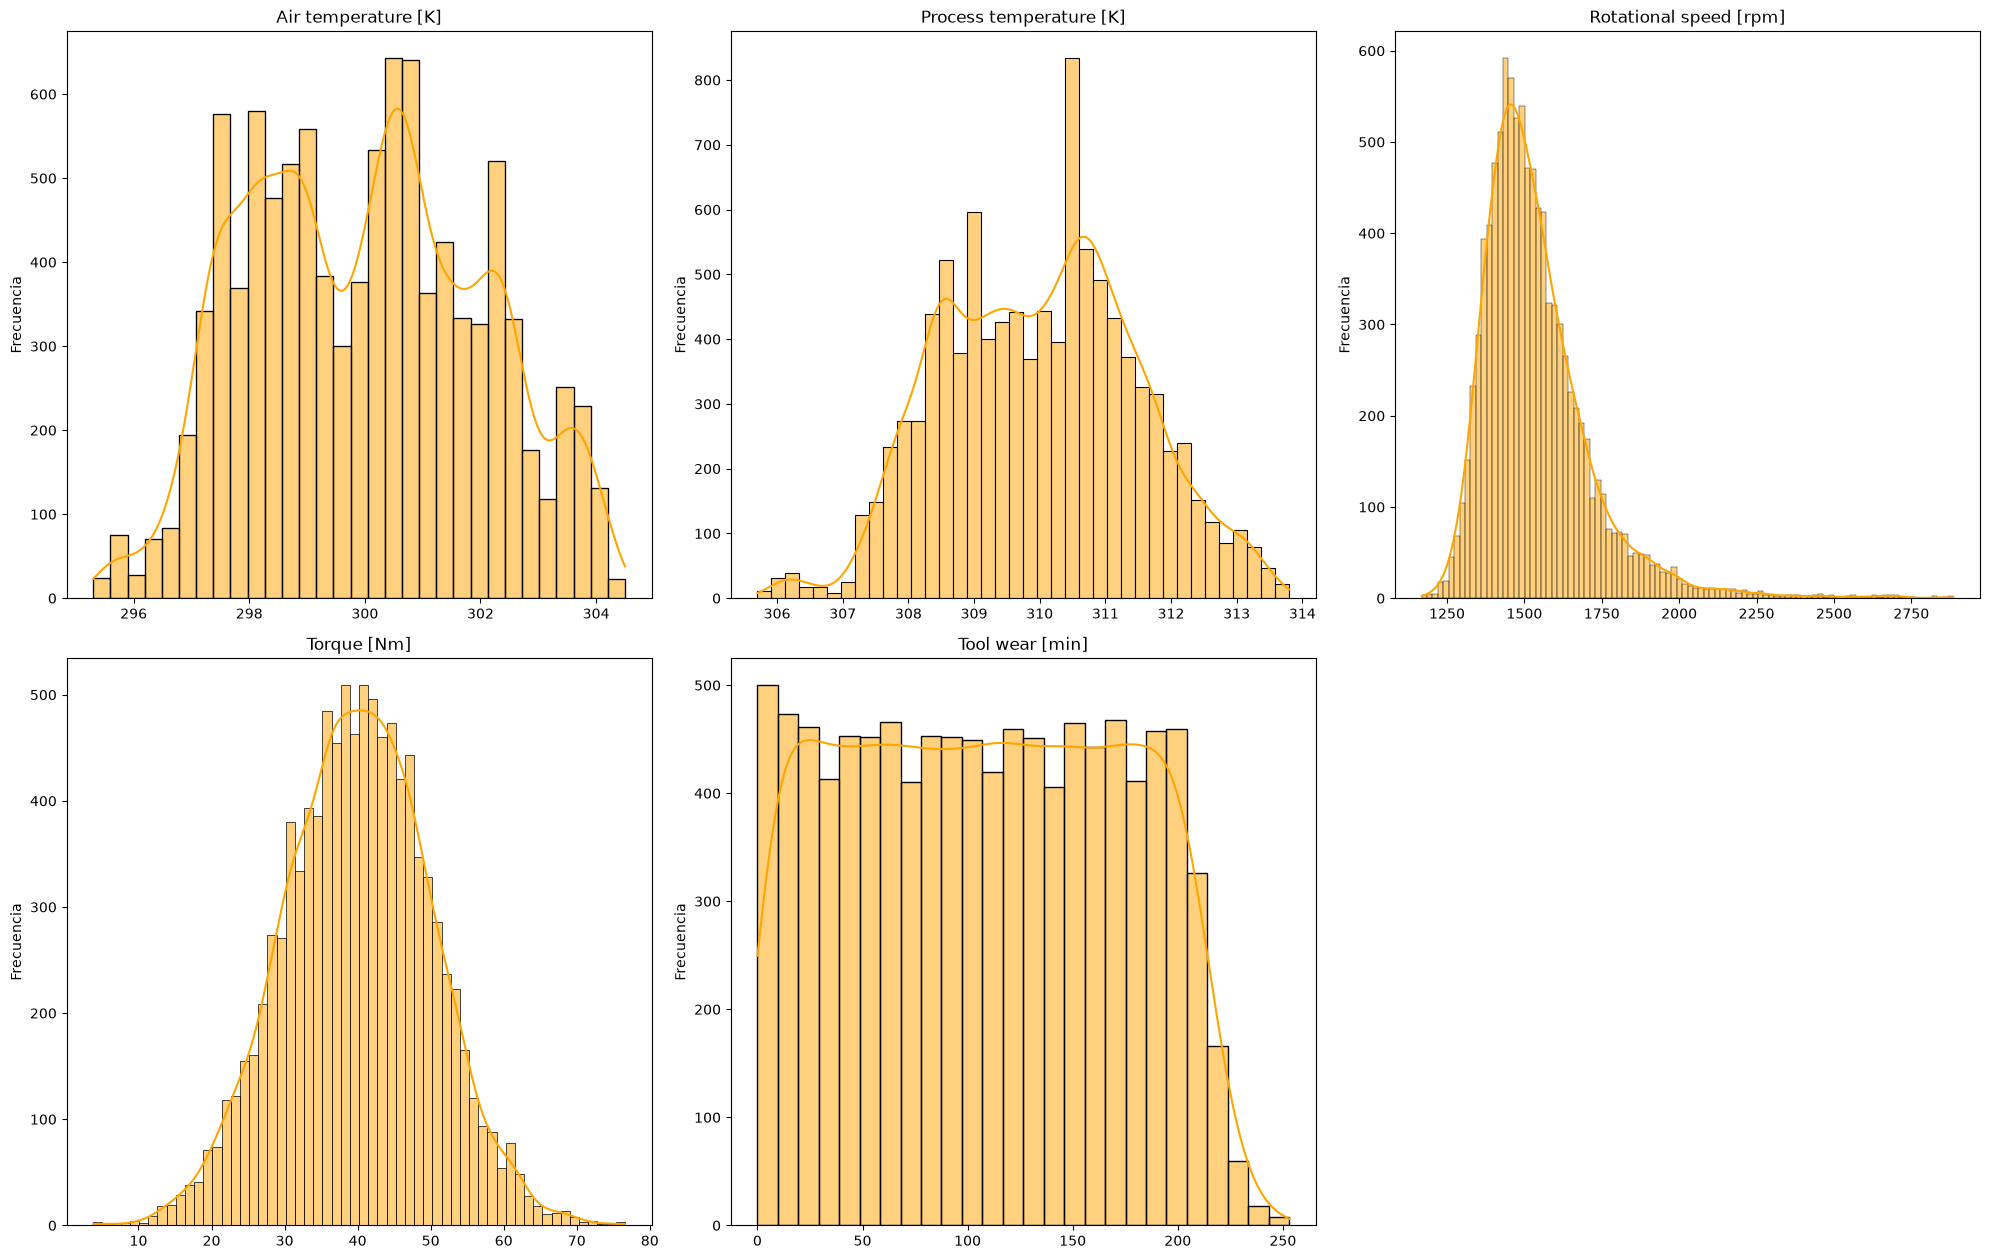

In [57]:
# Histogramas para ver la distribución de las variables numéricas
fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(20, 25)) #Arreglo matricial de 4*3
axes = axes.flatten() #Ajuste array
print('Histogramas de las columnas numéricas:')

for i, col in enumerate(num_cols):
    sns.histplot(x=maintenance_df[col], ax=axes[i], kde=True, color='orange')
    axes[i].set(title=f'{col}', xlabel=None, ylabel='Frecuencia') #Definición de títulos y ejes

# Eliminar las gráficas no usadas en la matriz 4x3
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

### Revisión de outliers

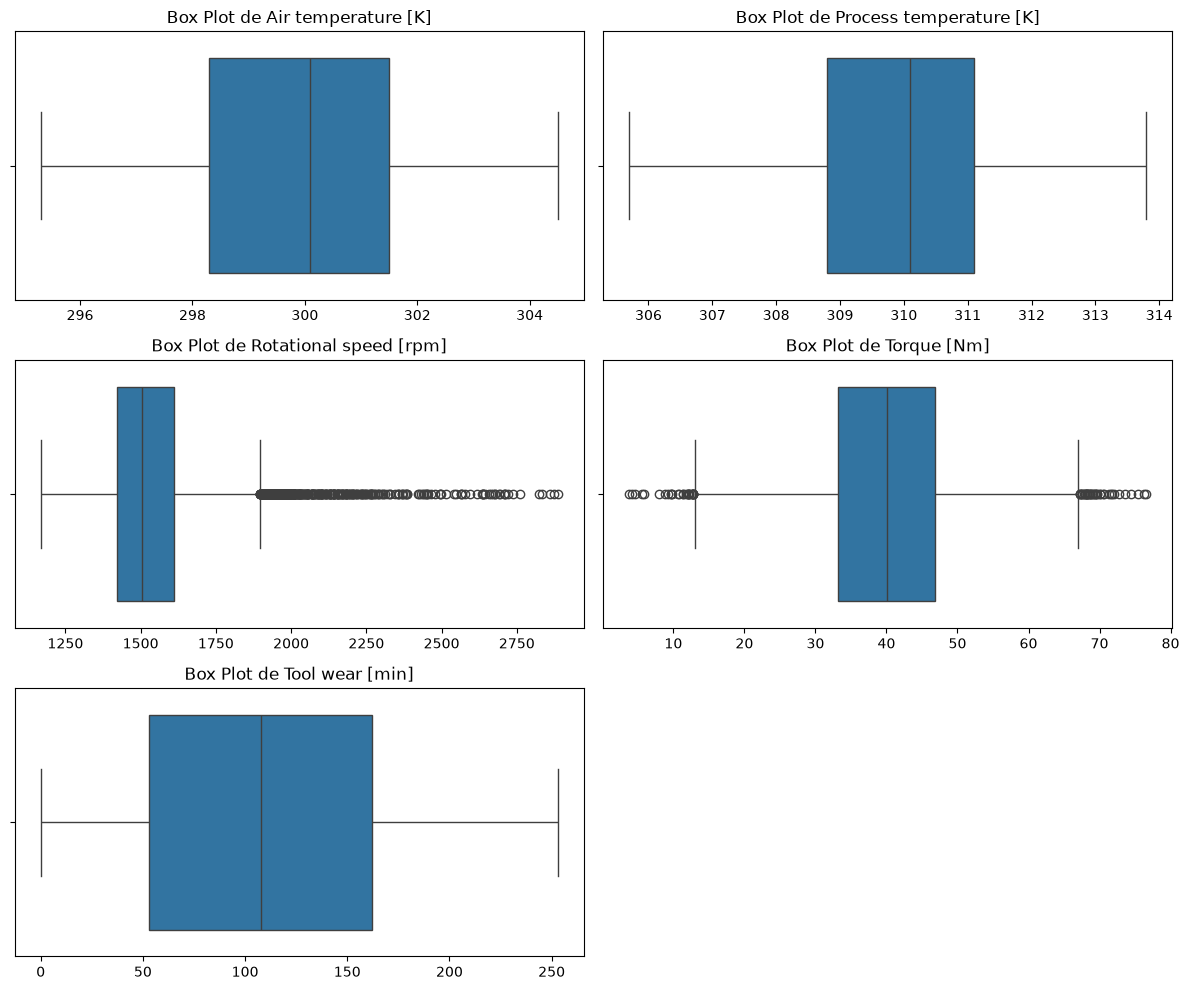

In [58]:
# Boxplots para ver la distribución de las variables numéricas
fig, axes = plt.subplots(3, 2, figsize=(12, 10))
axes = axes.flatten() # Ajuste array

for i, col in enumerate(num_cols):
    sns.boxplot(x=maintenance_df[col], ax=axes[i])
    axes[i].set_title(f'Box Plot de {col}') # Definición de títulos en el eje
    axes[i].set(xlabel=None, ylabel=None)


# Ocultar el último subplot sobrante (ya que son 5 variables y tenemos espacio para 6)
if len(num_cols) < len(axes):
    fig.delaxes(axes[-1])

plt.tight_layout()
plt.show() # Se muestra todo junto al terminar el ciclo

### Correlaciones entre las variables

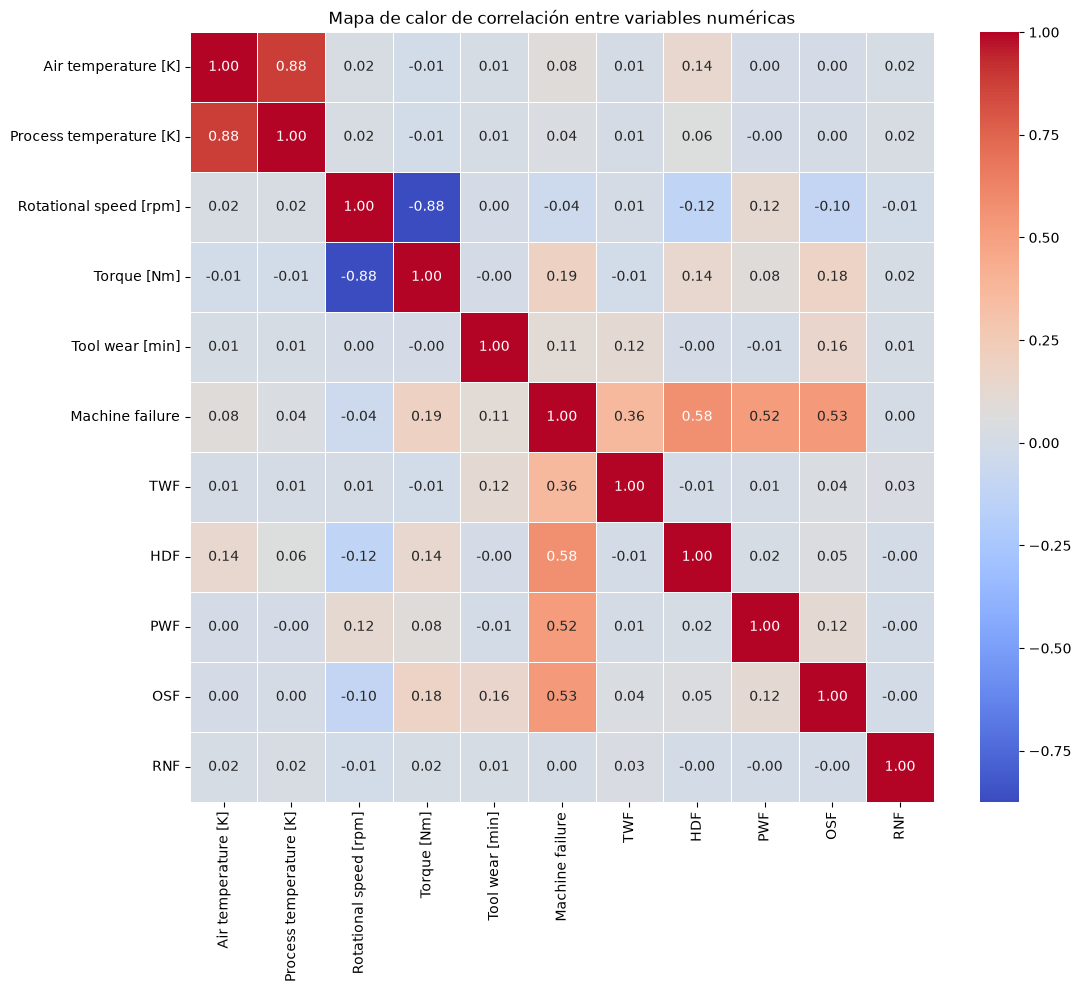

In [59]:
#Mapa de calor para ver la correlación entre las variables numéricas

# Excluimos los identificadores para limpiar la matriz
df_para_corr = maintenance_df.drop(columns=['UDI', 'Product ID'])
plt.figure(figsize=(12, 10))
sns.heatmap(df_para_corr.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Mapa de calor de correlación entre variables numéricas')
plt.show()


### Relación de las variables con falla

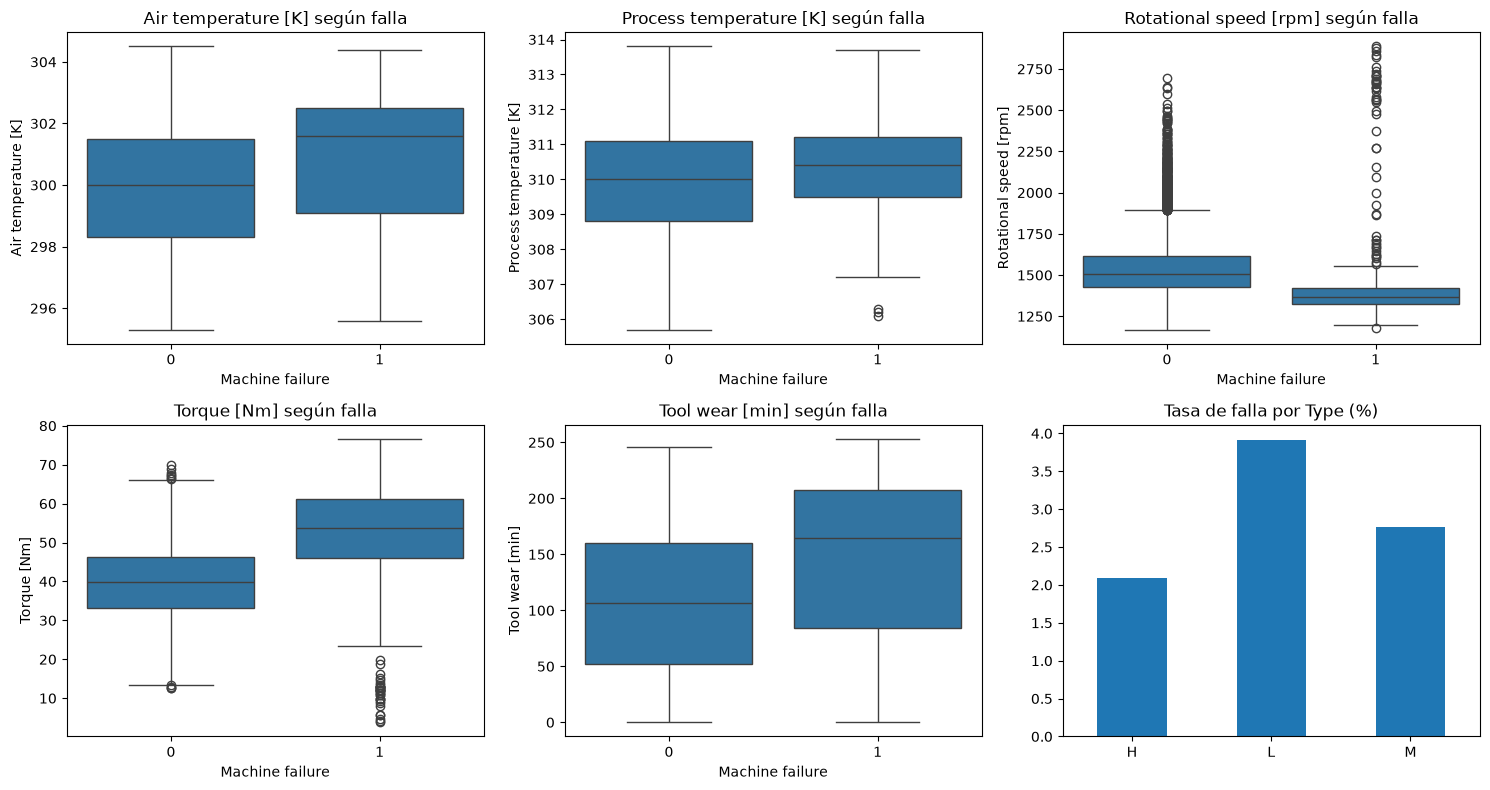

In [60]:
# Boxplot de cada variable según la falla (0 = sin falla, 1 = falla)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
ejes = axes.flatten()
for ax, col in zip(ejes, num_cols):
    sns.boxplot(data=maintenance_df, x='Machine failure', y=col, ax=ax)
    ax.set_title(f'{col} según falla')
    
# Último panel: tasa de falla (%) por tipo de producto
tasa_tipo = maintenance_df.groupby('Type')['Machine failure'].mean() * 100
tasa_tipo.plot(kind='bar', ax=ejes[5], title='Tasa de falla por Type (%)', rot=0)
ejes[5].set_xlabel('')
plt.tight_layout()
plt.show()

### Análisis y hallazgos

Las variables se encuentran en distintos rangos o escalas de valores continuos. Todos cuentan con 10,000 registros.

- Temperatura del aire va de un mínimo de 295.3 K a 304.5 K. Su distribución es aproximadamente simétrica (sesgo muy cercano a 0) con varios picos. Presenta  curtósis negativa (platicúrtica moderada), lo que indica que una distribución más achatada que una distribución mesocúrtica. Se puede ver tanto en el histograma como en el box plot que tiene colas son cortas y los datos se concentran en valores medios y hay ausencia de valores atípicos. 
- Temperatura del proceso va de un mínimo de 305.7 K a 313.8 K. De igual manera su distribución es aproximadamente simétrica (sesgo mínimo muy cercano a 0). El histograma presenta una curtósis negativa (platicúrtica leve), es decir las colas son cortas y los datos se concentran en una forma achatada. Se puede observar un pico en los valores entre 310 y 311. El bloxpot permite observar que no hay valores atípicos. 
- Velocidad rotacional, va de valores de 1168 rpm a 2886 rpm. Su distribución sesgada a la derecha, los valores se concentran en la parte inferior del rango. Tiene una curtósis positiva (leptocúrtica), es decir, una forma más picuda que la mesocúrtica y tiene una cola pronunciada a la derecha. Presenta valores atípicos en el rango superior.
- Torque va de un mínimo de 3.8 Nm a 76.6 Nm. Su distribución es aproximadamente simétrica y presenta una curtosis cercana a 0 (mesocúrtica). El histograma muestra una forma aproximadamente similar a una distribución normal. Presenta valores atípicos en ambos extremos. 
- Desgaste de herramental va de 0 a 253 min. Su distribución es aproximadamente uniforme, con una curtosis negativa (platicúrtica). Se puede ver en el histograma que los valores presentan una forma achatada, los datos se encuentran distribuidos nsin una concentración marcada en alguna zona específica del rango. No presenta valores atípicos relevantes.

- Variables booleanas presentan únicamente valores de 0 y 1, como se espera.

En cuanto a las variables categóricas
- Tipo cuenta con 3 valores L, M, H, no presenta valores fuera de las categorías esperadas.
- Product ID son 10,000 registros únicos.

Correlaciones que se pueden observar:

- Correlación entre Temperaturas: Se observa una correlación positiva muy alta (0.88) entre la Temperatura del aire y la Temperatura del proceso, lo cual hace total sentido físico, ya que el ambiente afecta directamente el calentamiento operativo de la máquina.   

- Relación Inversa: Existe una fuerte correlación negativa (-0.88) entre la velocidad rotacional (rpm) y el torque (Nm). Esta relación es consistente con el comportamiento esperado entre estas variables en el contexto del funcionamiento del motor.  

- Relación con la falla: la variable objetivo Machine failure presenta las mayores correlaciones con Torque (0.19) y Tool wear (0.11), mientras que las demás variables muestran correlaciones menores. Esto sugiere que estas variables pueden tener una relación más relevante con la ocurrencia de fallas y justifica analizarlas con mayor detalle durante la modelación.

- Al comparar descriptivamente las variables según la falla, las máquinas con falla muestran torque más alto (mediana ~54 Nm frente a ~40 Nm), mayor desgaste de herramienta (~165 min frente a ~107 min) y velocidades rotacionales más bajas (~1,370 rpm frente a ~1,500 rpm), con temperaturas ligeramente mayores. Por tipo de producto, la tasa de falla es mayor en L (~4%), seguida de M (~3%) y H (~2%), lo que sugiere que Type puede aportar información útil al modelo.

## Paso 3. Limpieza de datos

### Asignación de tipos de variable correctos

In [61]:
#Variables de identificación se convierten a tipo categórico
maintenance_df['UDI'] = maintenance_df['UDI'].astype('category') 
maintenance_df['Product ID'] = maintenance_df['Product ID'].astype('category')

#Variables numéricas se convierten a tipo float para su análisis
maintenance_df['Air temperature [K]'] = maintenance_df['Air temperature [K]'].astype('float')
maintenance_df['Process temperature [K]'] = maintenance_df['Process temperature [K]'].astype('float')
maintenance_df['Rotational speed [rpm]'] = maintenance_df['Rotational speed [rpm]'].astype('float')
maintenance_df['Torque [Nm]'] = maintenance_df['Torque [Nm]'].astype('float')
maintenance_df['Tool wear [min]'] = maintenance_df['Tool wear [min]'].astype('float')

#Variables objetivo se convierten a tipo int para su análisis
maintenance_df['Machine failure'] = maintenance_df['Machine failure'].astype('int') 
maintenance_df['TWF'] = maintenance_df['TWF'].astype('int')
maintenance_df['HDF'] = maintenance_df['HDF'].astype('int')
maintenance_df['PWF'] = maintenance_df['PWF'].astype('int')
maintenance_df['OSF'] = maintenance_df['OSF'].astype('int')
maintenance_df['RNF'] = maintenance_df['RNF'].astype('int')


Se realizaron conversiones explícitas (astype) para asegurar que las variables continuas sean de tipo flotante, las etiquetas de falla binarias sean enteras y los identificadores se manejen como categóricos.

No se utilizarán las variables de UDI a Product ID para efectos de entrenamiento del modelo ya que solo son variables de identificación. 

### Verificación de valores faltantes o duplicados

In [62]:
# Conteo de valores nulos por columna
print('Valores nulos por columna:')
maintenance_df.isnull().sum()

Valores nulos por columna:


UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [63]:
# Verificar si hay registros duplicados
print('Registros duplicados:')
print(maintenance_df.duplicated().sum())

Registros duplicados:
0


Verificamos que no hay presencia de valores faltantes en ninguna variable, por lo que no se requiere algún mecanismo de imputación de valores o eliminación de registros. Asimismo no se encontraron registros duplicados que requieran eliminarse.

### Tratamiento de outliers

Durante el análisis exploratorio se detectó que tanto Torque como Velocidad rotacional tienen valores atípicos, no se descartaran estos ni se les hará algún tratamiento debido a la naturaleza del problema. Por ahora, la hipótesis será que la presencia de estos valores atípicos puede resultar en una falla en la maquinaria que estamos analizando.


In [64]:
# Por variable: outliers por IQR (1.5 × IQR) y tasa de falla dentro y fuera de ellos
resumen = []
for col in ['Torque [Nm]', 'Rotational speed [rpm]']:
    q1, q3 = maintenance_df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    es_out = (maintenance_df[col] < q1 - 1.5*iqr) | (maintenance_df[col] > q3 + 1.5*iqr)
    resumen.append({
        'variable': col,
        'n_outliers': es_out.sum(),
        '% del total': es_out.mean() * 100,
        'tasa falla en outliers (%)': maintenance_df.loc[es_out, 'Machine failure'].mean() * 100,
        'tasa falla resto (%)': maintenance_df.loc[~es_out, 'Machine failure'].mean() * 100,
    })
pd.DataFrame(resumen).round(2)

,variable,n_outliers,% del total,tasa falla en outliers (%),tasa falla resto (%)
0,Torque [Nm],69,0.69,89.86,2.79
1,Rotational speed [rpm],418,4.18,8.37,3.17


La tabla muestra la tasa de falla dentro de los registros atípicos. Los 69 valores atípicos de torque (0.69% de los datos) presentaron falla en 89.86% de los casos, frente a 2.79% en el resto, es decir, una tasa unas 32 veces mayor. En velocidad rotacional, los 418 atípicos (4.18%) fallaron en 8.37% de los casos frente a 3.17%, unas 2.6 veces más. Los valores atípicos concentran información relevante sobre las fallas, por lo que se conservan y no se eliminan ni se transforman, ya que hacerlo quitaría del entrenamiento justamente los casos más informativos.

### Pipeline para el tratamiento de las variables

Para el pipeline se realizará un escalado de variables numéricas con la finalidad de mitigar el riesgo que un modelo le de mayor peso a una variable por la magnitud de su escala. Respecto a la variable Type, se realizará una transformación del tipo one-hot. Se definen aquí, pero se ajustan únicamente con el conjunto de entrenamiento después de la partición (Paso 4) para evitar data leakage. Se decide incluir Type como feature porque representa el nivel de calidad del producto, que puede influir en la falla, y se codifica con one-hot por ser categórica nominal sin orden.



### Verificación de consistencia entre Machine failure y modos de falla

In [65]:
# Verificar si Machine failure es consistente con los modos de falla
modos = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']
tiene_modo = maintenance_df[modos].sum(axis=1) > 0
pd.crosstab(maintenance_df['Machine failure'], tiene_modo,
            rownames=['Machine failure'], colnames=['Algún modo de falla'])

Algún modo de falla,False,True
Machine failure,,
0,9643,18
1,9,330


In [66]:
# Aislar los registros inconsistentes y ver qué modos aparecen
inconsistentes_a = maintenance_df[(maintenance_df['Machine failure'] == 0) & tiene_modo]
inconsistentes_b = maintenance_df[(maintenance_df['Machine failure'] == 1) & ~tiene_modo]

print("Modos presentes en los 18 registros con Machine failure = 0:")
print(inconsistentes_a[modos].sum())
print("\nRegistros con Machine failure = 1 sin modo de falla:", len(inconsistentes_b))

Modos presentes en los 18 registros con Machine failure = 0:
TWF     0
HDF     0
PWF     0
OSF     0
RNF    18
dtype: int64

Registros con Machine failure = 1 sin modo de falla: 9


Según la documentación del dataset, Machine failure debería valer 1 siempre que al menos un modo de falla esté activo. Sin embargo, se detectaron 27 registros (0.27%) que no cumplen esa regla:

- 18 registros con Machine failure = 0 y algún modo de falla activo. Todos corresponden a RNF (falla aleatoria), un evento que por definición ocurre sin relación con las condiciones del proceso, por lo que ninguna variable de entrada podría explicarlo.
- 9 registros con Machine failure = 1 y ningún modo de falla registrado.

Con la información disponible no es posible determinar cuál de las dos columnas es la correcta. Se decide conservar Machine failure tal como viene en el dataset por tres razones: el porcentaje de registros afectados es muy bajo, no se puede verificar el valor correcto sin acceso a la fuente de los datos, y los modos de falla no se utilizan como variables de entrada del modelo, ya que revelarían la variable objetivo y causarían fuga de información (data leakage). Se documenta como una limitación y como un punto a validar con el responsable de los datos en iteraciones futuras.

### Definición y Tratamiento de la Variable Objetivo (Baseline)

El dataset contiene múltiples variables relacionadas con las fallas:
- Machine failure es la variable general que indica si hay o no hay una falla. 
- Mientras que las 5 variables adicionales, especifican la causa raíz del fallo (TWF, HDF, PWF, OSF y RNF).

Para fines de esta actividad de construcción del modelo base, se toma la decisión estratégica de aislar como única variable objetivo a Machine failure, transformando el problema de multi-etiqueta a una clasificación binaria. Esto para simplificar el alcance, nos permitirá validar el flujo completo y la integración con MLFlow. Además que como fase inicial lo principal es detectar si una anomalía provocara el fallo de la máquina y posteriormente agregar la capa de complejidad para determinar la causa raíz de la falla. 

Las columnas TWF, HDF, PWF, OSF y RNF no se usarán como features, porque revelan la variable objetivo y causarían data leakage.


## Paso 4. Modelo Base

#### Análisis de distribución de clases y estrategia de partición

In [67]:
# Distribución de clases
maintenance_df['Machine failure'].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

In [68]:
# Proporción de clases (%)
print("Proporción de clases en el dataset (%):")
print(maintenance_df['Machine failure'].value_counts(normalize=True) * 100)

Proporción de clases en el dataset (%):
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


Al aislar la variable objetivo Machine failure, se observa un marcado desbalance en el conjunto de datos (la clase minoritaria de falla representa un porcentaje muy bajo frente al funcionamiento normal). Para garantizar que el modelo aprenda adecuadamente y que la evaluación sea estadísticamente representativa, se realiza una división estratificada de los datos en conjuntos de entrenamiento y prueba. Esto asegura que la proporción de fallas se conserve de forma equitativa tanto en los datos de entrenamiento como en los de evaluación, evitando sesgos por una distribución aleatoria desproporcionada.

### División del dataset en test y train

Se selecciona una proporción de división de 70% para entrenamiento y 30% para prueba. Esta proporción representa un balance óptimo: el 70% de los datos proporciona suficientes muestras de la clase minoritaria para que el modelo aprenda patrones representativos, mientras que el 30% restante asegura un conjunto de prueba estadísticamente robusto y confiable para evaluar el desempeño real del modelo ante datos no vistos.

In [69]:
# Separar las características (X) de la variable objetivo (y)
cat_cols = ['Type']
X = maintenance_df[num_cols + cat_cols] #Se toman las columnas numéricas y categóricas como características
y = maintenance_df['Machine failure']

# División estratificada 70% entrenamiento y 30% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.3,       # 30% para prueba
    random_state=42,     # Semilla para reproducibilidad
    stratify=y           # Asegurar que la proporción de clases se mantenga en ambos conjuntos
)

# Verificar que las proporciones se hayan conservado correctamente
print("Proporción de clases en el dataset completo:")
print(y.value_counts(normalize=True) * 100)

print("\nProporción de clases en y_train:")
print(y_train.value_counts(normalize=True) * 100)

print("\nProporción de clases en y_test:")
print(y_test.value_counts(normalize=True) * 100)



Proporción de clases en el dataset completo:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64

Proporción de clases en y_train:
Machine failure
0    96.614286
1     3.385714
Name: proportion, dtype: float64

Proporción de clases en y_test:
Machine failure
0    96.6
1     3.4
Name: proportion, dtype: float64


### Validación cruzada y elección de modelo

Se utiliza la estrategia de validación cruzada con la finalidad de obtener el mejor modelo base. Dado que el dataset presenta un desbalance severo con apenas un 3% de registros de la clase objetivo (fallas), se descartaron métricas como la precisión global o ROC-AUC que podrían dar valores optimistas sobre el rendimiento del modelo.

Se eligió utilizar el PR-AUC (Precision-Recall AUC) como métrica de evaluación del modelo, que permite analizar correctamente datasets que presentan clases desbalanceadas. 

In [70]:
# Validación cruzada con 5 pliegues
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

#Pipeline de preprocesamiento para estandarizar las variables numéricas y codificar las categóricas

def preprocesar():
    return ColumnTransformer([
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ])

# Selección de modelos base a comparar. Se utiliza class_weight = balanced para garantizar que los modelos tengan en cuenta el desbalance de clases en la variable objetivo.
modelos = {
    "Regresión Logística": Pipeline([
        ('prep', preprocesar()),
        ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
    ]),
    "Árbol de Decisión": Pipeline([
        ('prep', preprocesar()),
        ('clf', DecisionTreeClassifier(class_weight='balanced', random_state=42))
    ]),
    "Random Forest": Pipeline([
        ('prep', preprocesar()),
        ('clf', RandomForestClassifier(class_weight='balanced', random_state=42))
    ])
}

#Evaluación de cada modelo basado en la métrica PR-AUC (Average Precision), que es más adecuada para problemas de clasificación con clases desbalanceadas.
print("PR-AUC:")
for nombre, modelo in modelos.items():
    scores = cross_val_score(modelo, X_train, y_train, cv=cv, scoring='average_precision')
    print(f"- {nombre}: PR-AUC Promedio = {scores.mean():.4f} (+/- {scores.std():.4f})")

PR-AUC:
- Regresión Logística: PR-AUC Promedio = 0.4434 (+/- 0.0655)
- Árbol de Decisión: PR-AUC Promedio = 0.3949 (+/- 0.0598)
- Random Forest: PR-AUC Promedio = 0.7068 (+/- 0.0394)


Al evaluar los modelos mediante validación cruzada estratificada con 5-folds utilizando la métrica PR-AUC, se observa que Random Forest supera significativamente a los demás enfoques con un promedio de 0.7068 (con una desviación entre folds de 0.0394). Esto sugiere que los algoritmos de ensamblaje capturan de manera mucho más efectiva las relaciones no lineales entre las variables de operación de la máquina, estableciéndose como el modelo base (baseline) óptimo para avanzar hacia el registro y evaluación final.

## Referencias

Anthropic. (2026). Claude AI (Basado en Sonnet 5.5) [Modelo de lenguaje grande], utilizado para corrección de redacción, mejora de código y revisión de resultados. https://claude.ai

UCI Machine Learning. (2020). *AI4I 2020 Predictive Maintenance Dataset*. UC Irvine Machine Learning Repository. https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset